[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Buffers, Overlays and Clipping


## What you will be able to do

Draw a zone of a chosen distance around points and lines, cut two layers of polygons into the pieces
they make together with `overlay`, and trim a layer to a boundary with `clip`.

## The idea

### The problem

The forecasters want to know what lies within 50 km of each named station: how many stations, how much
land, and in which districts and countries. A radius of 50 km around Kirkenes reaches across two
borders, so the answer for Kirkenes is three pieces, one in each country, each with its own area.

None of the joins so far can produce those pieces. A spatial join pairs whole rows and keeps the
left table's geometry, so it can say that a zone touches Finland, and it cannot say how much of the
zone lies there. The answer needs new shapes, the zone itself, which no table holds yet, and the parts
of it that each country covers.

### A formal definition

> A **buffer** is the polygon of every point within a given distance of a geometry, so the buffer of a
> point is a circle and the buffer of a line is a corridor with rounded ends. An **overlay** combines
> two layers of polygons into new polygons cut along both layers' edges: `intersection` keeps the
> pieces that lie in both, `union` keeps every piece, `difference` keeps what lies in the first layer
> and outside the second, and `symmetric_difference` keeps what lies in exactly one. **Clipping** keeps
> the part of a layer that lies inside a boundary.

### Why it works that way

`buffer` takes a distance in the units of the CRS, so a 50 km zone is `buffer(50_000)` in UTM zone 33N.
The circle is drawn as a polygon with straight sides, 16 for each quarter of the circle by default,
so its area is a little less than πr². In degrees, the same call draws a circle in a space where a
degree of longitude and a degree of latitude have the same size, which on the ground is an ellipse
squeezed from east to west.

`overlay` works on the shapes, so its result has new geometries and a row for each piece, with the
columns of both rows that made it. Two layers that only share a border make pieces with no area, which are
lines, and `overlay` drops pieces of a different type from the first layer's, with a warning.
`clip` is the simpler tool when the second layer is only a boundary, since it trims the first layer,
keeps its columns and adds none from the boundary.

### Where this shows up

Service areas around stores, flood zones along rivers, the land within a set distance of a road. The
**Spatial Joins** notebook found that a district touching Sweden shares no measurable area with it,
and `overlay` returns the shared pieces themselves, as the last Common error shows. The **Dissolve and
Explode** notebook merges shapes that share a value into one, such as districts into regions.

### What this notebook covers

- buffers around points and around a line, and how round they are
- counting the stations inside each zone
- `overlay` with the districts and with the countries, and its four kinds
- `clip`
- four mistakes made with buffers and overlays

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
import geopandas as gpd
from shapely.geometry import Point, box

field = gpd.GeoDataFrame({"field": ["north"]}, geometry=[box(0, 0, 10, 10)])
wells = gpd.GeoDataFrame({"well": ["W1"]}, geometry=[Point(10, 5).buffer(3)])
pieces = gpd.overlay(wells, field, how="intersection")
print(pieces[["well", "field"]].assign(area=pieces.area.round(1)))
print("whole circle:", round(wells.area.iloc[0], 1))
```

```
  well  field  area
0   W1  north  14.1
whole circle: 28.2
```

A well on the field's edge has a zone of radius 3 around it, and half of the zone lies in the field.
The overlay's one piece carries the columns of both layers and its own area.

## Setup

Two libraries for the tables, GeoPandas and Shapely for the geometry, Matplotlib for the map, and the
standard library's `warnings`.

- `Path` finds the guide's copy of the country outlines, when the notebook runs beside it
- `warnings` catches the warnings `buffer` and `overlay` give
- `numpy` and `pandas` build the made-up register, and `numpy` gives π
- `geopandas` reads the outlines and does every buffer, overlay and clip, and the cell prints its
  version
- `shapely` builds the districts, a line between two stations and a test circle
- `matplotlib.pyplot` draws the map

`countries` holds the outlines of Denmark, Finland, Norway, Russia and Sweden, clipped to the Nordic
area, in degrees. Made with Natural Earth. The outlines come from Natural Earth's 1:50m map of the
world's countries, which is in the public domain.

`stations` is the register of 300 stations as a GeoDataFrame in degrees, and `named` holds the five
named stations at their real positions. `districts` holds the eight forecast districts in UTM zone
33N, in meters. The stations and the districts are made up. The stations are drawn at random over
mainland Norway from a fixed seed, and the districts are drawn around eight chosen centers and cut to
Norway's outline.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)

named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

districts = forecast_districts()
print("geopandas", gpd.__version__, "|", len(stations), "made-up stations,", len(named), "named stations,",
      len(districts), "made-up districts")

geopandas 1.2.0 | 300 made-up stations, 5 named stations, 8 made-up districts


## Worked examples

### A zone of 50 km around each named station

Everything is converted to UTM zone 33N first, so that a distance of 50,000 is 50 km.

In [2]:
named_m = named.to_crs(25833)
stations_m = stations.to_crs(25833)
countries_m = countries.to_crs(25833)
zones = named_m[["name", "geometry"]].assign(geometry=named_m.buffer(50_000))
print(zones.geom_type.tolist())
print("area of each zone (km²):", (zones.area / 1e6).round(1).tolist())
print("π × 50²:", round(np.pi * 50**2, 1))

['Polygon', 'Polygon', 'Polygon', 'Polygon', 'Polygon']
area of each zone (km²): [7841.4, 7841.4, 7841.4, 7841.4, 7841.4]
π × 50²: 7854.0


Each zone is a polygon of 7,841.4 km², a little less than the 7,854.0 km² of a true circle, because
the circle is drawn with straight sides. `quad_segs` sets how many sides each quarter of the circle
gets.

In [3]:
for quad_segs in [1, 2, 4, 16, 64]:
    circle = shapely.buffer(shapely.Point(0, 0), 50_000, quad_segs=quad_segs)
    print(f"quad_segs={quad_segs:<3} corners: {shapely.get_num_coordinates(circle) - 1:<4}"
          f"area: {circle.area / 1e6:.1f} km²")

quad_segs=1   corners: 4   area: 5000.0 km²
quad_segs=2   corners: 8   area: 7071.1 km²
quad_segs=4   corners: 16  area: 7653.7 km²
quad_segs=16  corners: 64  area: 7841.4 km²
quad_segs=64  corners: 256 area: 7853.2 km²


With one segment for each quarter the "circle" is a square standing on a corner, 5,000 km². The default
of 16 gives 64 corners and comes within 0.2% of the true area, and 64 comes closer still for four times
as many corners.

### Counting the stations inside each zone

A zone is an ordinary polygon, so a spatial join counts the stations in it.

In [4]:
inside = gpd.sjoin(stations_m, zones)
inside.groupby("name").size().reindex(named["name"], fill_value=0)

name
Bergen      4
Oslo        5
Svalbard    0
Tromso      4
Kirkenes    4
dtype: int64

Only 17 of the 300 stations lie within 50 km of a named station, five of them near Oslo and none near
Svalbard, whose zone holds no mainland station.

### A corridor along a line

The buffer of a line is a corridor of the given half-width along it, with rounded ends.

In [5]:
route = gpd.GeoDataFrame({"route": ["Bergen to Oslo"]},
                         geometry=[shapely.LineString([named_m.geometry.iloc[0], named_m.geometry.iloc[1]])],
                         crs=25833)
corridor = route.assign(geometry=route.buffer(20_000))
print("line length:", round(route.length.iloc[0] / 1000, 1), "km")
print("corridor area:", round(corridor.area.iloc[0] / 1e6), "km²")
print("stations in the corridor:", len(gpd.sjoin(stations_m, corridor)))

line length: 306.7 km
corridor area: 13522 km²
stations in the corridor: 14


The straight line from Bergen to Oslo is 306.7 km long, and a corridor 20 km to either side covers
13,522 km² and holds 14 stations.

### Overlay with the districts

`overlay` with `how="intersection"` cuts each zone along the districts' edges and keeps the pieces
that lie in both.

In [6]:
by_district = gpd.overlay(zones, districts, how="intersection")
by_district.assign(km2=(by_district.area / 1e6).round(1))[["name", "district", "km2"]]

,name,district,km2
0,Bergen,West,4331.1
1,Oslo,East,7665.6
2,Svalbard,Svalbard,5222.4
3,Tromso,Far North,4779.8
4,Kirkenes,Northeast,3552.9


Each zone falls in a single district, and each piece is the part of the zone on land, since the
districts cover only Norway's land. Oslo's piece is 7,665.6 km², almost the whole zone, and Kirkenes's
is 3,552.9 km², less than half, because much of its zone lies in the sea or across the border.

### Overlay with the countries

The countries show where Kirkenes's zone goes.

In [7]:
kirkenes = gpd.overlay(zones[zones["name"] == "Kirkenes"], countries_m[["ADMIN", "geometry"]],
                       how="intersection")
kirkenes.assign(km2=(kirkenes.area / 1e6).round(0))[["name", "ADMIN", "km2"]]

,name,ADMIN,km2
0,Kirkenes,Finland,445.0
1,Kirkenes,Norway,3553.0
2,Kirkenes,Russia,1473.0


Of the zone's 7,841 km², 3,553 lie in Norway, 1,473 in Russia and 445 in Finland. The rest is sea,
which `difference` returns.

In [8]:
sea = gpd.overlay(zones, countries_m[["ADMIN", "geometry"]], how="difference")
sea.assign(km2=(sea.area / 1e6).round(0))[["name", "km2"]]

,name,km2
0,Bergen,3510.0
1,Oslo,176.0
2,Svalbard,2619.0
3,Tromso,3062.0
4,Kirkenes,2370.0


`difference` keeps the part of each zone outside every country. Kirkenes's 2,370 km² of sea and its
three pieces on land add up to its 7,841 km². Oslo's zone has the least sea, 176 km², at the head of
the Oslofjord.

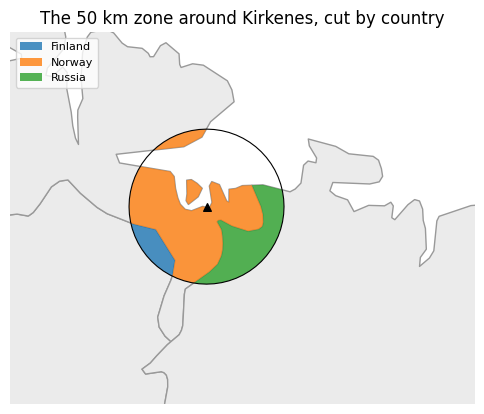

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
countries_m.plot(ax=ax, color="0.92", edgecolor="0.6")
kirkenes.plot(ax=ax, column="ADMIN", categorical=True, alpha=0.8, legend=True,
              legend_kwds={"loc": "upper left", "fontsize": 8})
zones[zones["name"] == "Kirkenes"].boundary.plot(ax=ax, color="black", linewidth=0.8)
named_m[named_m["name"] == "Kirkenes"].plot(ax=ax, color="black", marker="^", markersize=30)
ax.set_xlim(950_000, 1_250_000)
ax.set_ylim(7_680_000, 7_920_000)
ax.set_axis_off()
ax.set_title("The 50 km zone around Kirkenes, cut by country")
plt.show()

The black circle is the whole zone, and the colored pieces are the overlay's three rows, one for each
country. The white part of the circle, inside the black line and outside every piece, is the sea that
`difference` measured.

### The four kinds of overlay

Each `how` keeps a different set of pieces.

In [10]:
for how in ["intersection", "union", "difference", "symmetric_difference"]:
    result = gpd.overlay(zones, districts, how=how)
    print(f"{how:<21} {len(result):>2} pieces, {result.area.sum() / 1e6:>9,.0f} km², columns: {list(result.columns)}")
union = gpd.overlay(zones, districts, how="union")
union.iloc[[4, 9, 16]].assign(km2=(union.iloc[[4, 9, 16]].area / 1e6).round(0)).drop(columns="geometry")

intersection           5 pieces,    25,552 km², columns: ['name', 'district', 'geometry']
union                 18 pieces,   400,552 km², columns: ['name', 'district', 'geometry']
difference             5 pieces,    13,655 km², columns: ['name', 'geometry']
symmetric_difference  13 pieces,   375,000 km², columns: ['name', 'district', 'geometry']


,name,district,km2
4,Kirkenes,Northeast,3553.0
9,Kirkenes,NaN,4289.0
16,NaN,Northeast,44970.0


`intersection` keeps the five pieces in both layers. `union` keeps all 18 pieces of both, the parts of
the zones outside the districts included, and its area is the area of everything either layer covers.
`difference` keeps the five pieces of the zones outside the districts, with only the zones' columns,
and `symmetric_difference` keeps the 13 pieces that lie in one layer and not the other.

The three rows of the union printed under the counts are Kirkenes's three kinds of piece. The first
lies in both the zone and Northeast, the second in the zone outside every district, and the third in
Northeast outside the zone. Where a piece comes from one layer only, the other layer's column is
`NaN`.

### Clip

`clip` trims a layer to a boundary and keeps only the first layer's columns.

In [11]:
norway = countries_m[countries_m["ADMIN"] == "Norway"]
on_land = zones.clip(norway)
print(list(on_land.columns))
on_land.assign(km2=(on_land.area / 1e6).round(0)).sort_values("name")[["name", "km2"]]

['name', 'geometry']


,name,km2
0,Bergen,4331.0
4,Kirkenes,3553.0
1,Oslo,7666.0
2,Svalbard,5222.0
3,Tromso,4780.0


The areas match the overlay with Norway, for example 3,553 km² for Kirkenes, and the result has no
`ADMIN` column, since `clip` adds nothing from the boundary. It also returns the rows in its own order,
so the cell sorts them by name. A box works as a boundary too.

In [12]:
south = countries_m.clip(shapely.box(-100_000, 6_400_000, 700_000, 7_100_000))
south.assign(km2=(south.area / 1e6).round(0))[["ADMIN", "km2"]]

,ADMIN,km2
0,Denmark,55.0
4,Sweden,217760.0
2,Norway,194480.0


The box keeps southern Norway, part of Sweden and a sliver of Denmark, 55 km² of its northern tip.

### Shrinking with a negative buffer

A negative distance moves a polygon's edge inward.

In [13]:
core = districts.assign(geometry=districts.buffer(-20_000))
pd.DataFrame({"district": districts["district"],
              "km2": (districts.area / 1e6).round(0),
              "more_than_20_km_inside": (core.area / 1e6).round(0)})

,district,km2,more_than_20_km_inside
0,South,36056.0,20043.0
1,East,62504.0,41113.0
2,West,53904.0,17185.0
3,Mid,61575.0,28233.0
4,North,30984.0,7023.0
5,Far North,31283.0,4115.0
6,Northeast,48523.0,14064.0
7,Svalbard,62068.0,10811.0


Far North keeps 4,115 km² of its 31,283, because most of it is a narrow strip of coast and islands,
and East keeps 41,113 km² of its 62,504.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/10-buffers-overlays-and-clipping-solutions.ipynb).

**1.** Draw a 100 km zone around Tromso and print its area in square kilometers, rounded to a whole number.

In [14]:
# your code here

**2.** Count the stations within 30 km of Oslo, using a buffer and a spatial join.

In [15]:
# your code here

**3.** Use `overlay` to find how many square kilometers of each district lie within 50 km of any named station, and print them for every district, with 0 where none does.

In [16]:
# your code here

**4.** Find how many square kilometers of Tromso's 50 km zone lie in Norway, with `overlay` and `how="intersection"`.

In [17]:
# your code here

**5.** Draw a map of the West district with the 20 km corridor from Bergen to Oslo and the stations inside the corridor.

In [18]:
# your code here

## Common errors

### `UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect.`

The named stations get a zone of half a degree, in degrees.

In [19]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", UserWarning)
    half_degree = named.buffer(0.5)
for warning in caught:
    print(f"{warning.category.__name__}: {str(warning.message).splitlines()[0]}")
size = half_degree.to_crs(25833).bounds
print("east to west (km):  ", ((size["maxx"] - size["minx"]) / 1000).round(0).tolist())
print("north to south (km):", ((size["maxy"] - size["miny"]) / 1000).round(0).tolist())

east to west (km):   [57.0, 56.0, 23.0, 39.0, 47.0]
north to south (km): [111.0, 111.0, 112.0, 111.0, 109.0]


Half a degree of latitude is about 56 km everywhere, so every zone is about 111 km from north to
south. Half a degree of longitude is shorter the farther north it is, so the zones are 57 km wide at
Bergen and 23 km at Svalbard, ellipses of different sizes. Convert to a CRS in meters and buffer by a
distance in meters, as the worked examples did.

### `NotImplementedError: overlay currently only implemented for GeoDataFrames`

Only Norway's outline is wanted from the countries, and it is passed as a column of shapes.

In [20]:
named_m = named.to_crs(25833)
countries_m = countries.to_crs(25833)
zones = named_m[["name", "geometry"]].assign(geometry=named_m.buffer(50_000))
norway_outline = countries_m[countries_m["ADMIN"] == "Norway"].geometry
print(type(norway_outline).__name__)
gpd.overlay(zones, norway_outline, how="intersection")

GeoSeries


NotImplementedError: overlay currently only implemented for GeoDataFrames

`overlay` takes two GeoDataFrames, and selecting the `geometry` column gives a GeoSeries. Keep a
GeoDataFrame by selecting a list of columns, `countries_m[["ADMIN", "geometry"]]`, or use `clip`,
which accepts a GeoSeries or a single shape as its boundary.

In [21]:
print(len(gpd.overlay(zones, countries_m[countries_m["ADMIN"] == "Norway"][["ADMIN", "geometry"]])), "pieces")
print(len(zones.clip(norway_outline)), "clipped zones")

5 pieces
5 clipped zones


### ``ValueError: `how` was 'intersect' but is expected to be in ['intersection', 'union', 'identity', 'symmetric_difference', 'difference']``

In [22]:
zones = named.to_crs(25833)[["name", "geometry"]]
zones["geometry"] = zones.buffer(50_000)
gpd.overlay(zones, districts, how="intersect")

ValueError: `how` was 'intersect' but is expected to be in ['intersection', 'union', 'identity', 'symmetric_difference', 'difference']

The kind of overlay is a noun, `intersection`, and the message lists the five accepted names. The
fifth, `identity`, keeps the pieces of the first layer, cut where the second layer's edges cross them.

### ``UserWarning: `keep_geom_type=True` in overlay resulted in 7 dropped geometries of different geometry types than df1 has.``

The districts are overlaid with the countries.

In [23]:
countries_m = countries.to_crs(25833)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", UserWarning)
    kept = gpd.overlay(districts, countries_m[["ADMIN", "geometry"]], how="intersection")
for warning in caught:
    print(f"{warning.category.__name__}: {str(warning.message).splitlines()[0]}")
every_piece = gpd.overlay(districts, countries_m[["ADMIN", "geometry"]], how="intersection",
                          keep_geom_type=False)
print("kept:", len(kept), "| every piece:", every_piece.geom_type.value_counts().sort_index().to_dict())
print("area kept:", round(kept.area.sum() / 1e6, 1), "km² | area of the districts:", round(districts.area.sum() / 1e6, 1), "km²")
slivers = kept[kept["ADMIN"] != "Norway"]
print("outside Norway:", list(zip(slivers["district"], slivers["ADMIN"])),
      "| each under 1 mm²:", bool((slivers.area < 1e-6).all()))

kept: 10 | every piece: {'GeometryCollection': 2, 'MultiLineString': 5, 'MultiPolygon': 7, 'Polygon': 1}
area kept: 386896.9 km² | area of the districts: 386896.9 km²
outside Norway: [('East', 'Sweden'), ('Mid', 'Sweden')] | each under 1 mm²: True


The districts share their border with Sweden, Finland and Russia, and an intersection along a shared
border is a line. `overlay` keeps pieces of the first layer's type, polygons, and drops the lines, with
this warning. With `keep_geom_type=False` the result holds 15 pieces, five of them lines and two of
them collections that mix lines with a sliver of polygon. The 10 rows kept are the eight districts'
pieces in Norway and two slivers in Sweden, for East and Mid, each smaller than a square millimeter.
The warning's count of 7 takes in the five line pieces and the two collections. The polygons kept add
up to the districts' whole area, so nothing with an area was lost, and the warning here reports borders. When the dropped
pieces matter, pass `keep_geom_type=False` and look at them, as the cell does.

## Recap

- You can draw a zone around points or lines with `buffer`, in a CRS measured in meters, and set how
  round it is with `quad_segs`.
- You can count what lies inside a zone with a spatial join.
- You can cut two layers into pieces with `overlay`, and choose the pieces with `how`.
- You can trim a layer to a boundary with `clip`, which keeps only the first layer's columns.
- You can shrink a polygon with a negative buffer.

## What is next

The **Dissolve and Explode** notebook merges shapes that share a value into one, and splits a shape of
many parts into a row for each.

---

&#8592; **Previous:** [Nearest Neighbors](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/09-nearest-neighbors.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)
